# CSE558: Data Science — Assignment 1
## Dimensionality Reduction and Random Projections for K-Means and Linear Regression

* **Group Members:**
  * **Atharv Goel** (Roll Number: **MT26155**)
  * **Ishwaani Batra** (Roll Number: **MT26166**)
* **Submission File:** `MT26155-MT26166-DSA1.zip`
* **Declaration:** We declare that all answers and code submitted in this notebook are our own original work. All external documentation and references consulted have been appropriately cited.
* **Reproducibility:** All random seeds and initialisations are strictly fixed so that every number, table, and figure can be independently and deterministically reproduced.


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import os
import sklearn

from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans

# Fix master random seed for top-level reproducibility
SEED = 42
np.random.seed(SEED)

# Separate projection dimensions for Q1 and Q2 to prevent variable clashes
m_values_q1 = [5, 10, 15, 20, 25]
m_values_q2 = [50, 100, 200, 500, 1000, 2000, 5000]

# Create output directories for tables, figures, and cached data
os.makedirs("data", exist_ok=True)
os.makedirs("outputs/question1", exist_ok=True)
os.makedirs("outputs/question2", exist_ok=True)


print("Scikit-learn Version:", sklearn.__version__)
print("Q1 Projection Dimensions (m):", m_values_q1)
print("Q2 Sketch Dimensions (m):", m_values_q2)


Scikit-learn Version: 1.6.1
Q1 Projection Dimensions (m): [5, 10, 15, 20, 25]
Q2 Sketch Dimensions (m): [50, 100, 200, 500, 1000, 2000, 5000]


In [15]:
# Download and load the default 10% KDD Cup 1999 dataset
kdd = fetch_kddcup99(
    subset=None,
    as_frame=True,
    data_home="./data"
)

print("Dataset loaded successfully!")
print("Feature matrix shape:", kdd.data.shape)
print("Target vector shape:", kdd.target.shape)

print("\nFirst 5 connections in the dataset:")
display(kdd.data.head())

print("\nTop 10 connection label counts:")
display(kdd.target.value_counts().head(10).to_frame(name="Count"))

Dataset loaded successfully!
Feature matrix shape: (494021, 41)
Target vector shape: (494021,)

First 5 connections in the dataset:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0,b'tcp',b'http',b'SF',181,5450,0,0,0,0,...,9,9,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0
1,0,b'tcp',b'http',b'SF',239,486,0,0,0,0,...,19,19,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0
2,0,b'tcp',b'http',b'SF',235,1337,0,0,0,0,...,29,29,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0
3,0,b'tcp',b'http',b'SF',219,1337,0,0,0,0,...,39,39,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0
4,0,b'tcp',b'http',b'SF',217,2032,0,0,0,0,...,49,49,1.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0



Top 10 connection label counts:


,Count
labels,
b'smurf.',280790
b'neptune.',107201
b'normal.',97278
b'back.',2203
b'satan.',1589
b'ipsweep.',1247
b'portsweep.',1040
b'warezclient.',1020
b'teardrop.',979


In [16]:
categorical_cols = ['protocol_type', 'service', 'flag']

numerical_cols = [
    col for col in kdd.data.columns
    if col not in categorical_cols
]

print("Categorical features (3):", categorical_cols)
print("Numerical features (38):", len(numerical_cols))

# 1. Convert 38 numerical features to float32
X_num = kdd.data[numerical_cols].to_numpy(dtype=np.float32)

# 2. One-hot encode the 3 text categorical features
X_cat = pd.get_dummies(
    kdd.data[categorical_cols],
    dtype=np.float32
).to_numpy(dtype=np.float32)

print("\nNumerical matrix shape:", X_num.shape)
print("Categorical matrix shape:", X_cat.shape)

# 3. Concatenate numerical and one-hot encoded matrices
D_raw = np.concatenate([X_num, X_cat], axis=1)
print("Combined raw matrix shape:", D_raw.shape)

# 4. Identify and drop constant columns (where max == min across all rows)
col_min = D_raw.min(axis=0)
col_max = D_raw.max(axis=0)

nonconstant = col_max > col_min
num_dropped = np.sum(~nonconstant)
print(f"Constant columns dropped: {num_dropped}")

D_raw = D_raw[:, nonconstant]
col_min = col_min[nonconstant]
col_max = col_max[nonconstant]

# 5. Rescale each column to [0, 1] via x -> (x - min) / (max - min)
D = (D_raw - col_min) / (col_max - col_min)
D = D.astype(np.float32)

# 6. Binary classification target vector for Question 2
# y_i = 1 if attack (not b'normal.'), y_i = 0 if normal
y = (kdd.target != b'normal.').to_numpy(dtype=float)

# Save processed matrices for fast reuse
np.save("data/D.npy", D)
np.save("data/y.npy", y)

# Final verification
n, d = D.shape
print("\n========== PROCESSED DATASET SPECIFICATIONS ==========")
print(f"Number of rows (n): {n}")
print(f"Number of columns (d): {d}")
print(f"Matrix D data type: {D.dtype}")
print(f"Target vector y shape: {y.shape}")
print(f"Normal connections (y == 0): {np.sum(y == 0):,}")
print(f"Attack connections (y == 1): {np.sum(y == 1):,}")
print(f"Value range in D: [{D.min():.1f}, {D.max():.1f}]")
print(f"Any NaN values present: {np.isnan(D).any()}")
print(f"Any Infinite values present: {np.isinf(D).any()}")


Categorical features (3): ['protocol_type', 'service', 'flag']
Numerical features (38): 38

Numerical matrix shape: (494021, 38)
Categorical matrix shape: (494021, 80)
Combined raw matrix shape: (494021, 118)
Constant columns dropped: 2

========== PROCESSED DATASET SPECIFICATIONS ==========
Number of rows (n): 494021
Number of columns (d): 116
Matrix D data type: float32
Target vector y shape: (494021,)
Normal connections (y == 0): 97,278
Attack connections (y == 1): 396,743
Value range in D: [0.0, 1.0]
Any NaN values present: False
Any Infinite values present: False


### Preprocessing Summary & Dataset Dimensions

Following the assignment instructions, we constructed the data matrix **D** from `kdd.data`:
1. **One-Hot Encoding:** The 3 text features (`protocol_type`, `service`, and `flag`) were one-hot encoded into 80 binary columns. Combined with the 38 numerical features, this yielded an initial matrix of 118 columns.
2. **Dropping Constant Features:** Exactly **2 columns** had identical values across all 494,021 rows (`num_outbound_cmds` and `is_host_login`, both all zeros) and were removed.
3. **Min-Max Rescaling:** All remaining columns were rescaled to the unit interval [0, 1] via the transformation **x ↦ (x − min) / (max − min)**, stored in memory as `float32`.
4. **Final Dimensions:**
   * **Number of rows (n):** **494,021**
   * **Number of columns (d):** **116**
   * The matrix **D ∈ ℝ⁴⁹⁴⁰²¹ ˣ ¹¹⁶** contains no missing or invalid values.
5. **Target Vector (y):** A binary array **y ∈ {0, 1}⁴⁹⁴⁰²¹** where **yᵢ = 0** corresponds to normal traffic (97,278 connections) and **yᵢ = 1** indicates a network attack (396,743 connections).

In [17]:
# Consistent float64 cost calculation function
# Evaluates cost(X, centers) = sum_{i=1}^n min_{b in centers} ||X_i - b||_2^2
# Uses chunking in float64 to completely eliminate float32 numerical noise and prevent memory spikes

def calculate_original_cost(X, centers, chunk_size=20000):
    total_cost = 0.0
    centers64 = centers.astype(np.float64)
    center_norms = np.sum(centers64**2, axis=1)

    for start in range(0, X.shape[0], chunk_size):
        end = min(start + chunk_size, X.shape[0])
        chunk = X[start:end].astype(np.float64)

        distances = (
            np.sum(chunk**2, axis=1)[:, None]
            + center_norms[None, :]
            - 2.0 * (chunk @ centers64.T)
        )
        distances = np.maximum(distances, 0.0)
        total_cost += np.sum(np.min(distances, axis=1))

    return total_cost

print("Consistent float64 clustering cost function defined successfully!")


Consistent float64 clustering cost function defined successfully!


In [18]:
# ==============================================================================
# QUESTION 1(a): BASELINE K-MEANS ON ORIGINAL DATA MATRIX D
# ==============================================================================

k = 15

# Instantiate KMeans with strictly specified parameters: k=15, n_init=5
kmeans_D = KMeans(
    n_clusters=k,
    n_init=5,
    random_state=SEED
)

# Time the full k-means execution on D
start_time = time.perf_counter()
kmeans_D.fit(D)
end_time = time.perf_counter()

time_D = end_time - start_time
B = kmeans_D.cluster_centers_
C_D = kmeans_D.labels_

# Cross-check sklearn's float32 internal inertia
inertia_crosscheck = kmeans_D.inertia_

# Recompute baseline cost with our exact float64 cost function
cost_D = calculate_original_cost(D, B)

# Save baseline results
np.save("outputs/question1/original_centres.npy", B)
np.save("outputs/question1/original_labels.npy", C_D)

print("========== QUESTION 1(a) BASELINE RESULTS ==========")
print(f"Number of clusters (k): {k}")
print(f"Number of initialisations (n_init): 5")
print(f"Recomputed Baseline Cost cost(D, B) [float64]: {cost_D:.6f}")
print(f"Scikit-learn Inertia (float32 cross-check): {inertia_crosscheck:.6f}")
print(f"Wall-clock execution time: {time_D:.4f} seconds")

# Display cluster point distribution
cluster_counts_df = pd.DataFrame({
    "Cluster": [f"Cluster {i}" for i in range(k)],
    "Point Count": np.bincount(C_D, minlength=k)
})
display(cluster_counts_df)


========== QUESTION 1(a) BASELINE RESULTS ==========
Number of clusters (k): 15
Number of initialisations (n_init): 5
Recomputed Baseline Cost cost(D, B) [float64]: 53500.906745
Scikit-learn Inertia (float32 cross-check): 53474.089844
Wall-clock execution time: 22.6698 seconds


,Cluster,Point Count
0,Cluster 0,280781
1,Cluster 1,86925
2,Cluster 2,30321
3,Cluster 3,1272
4,Cluster 4,20474
5,Cluster 5,8477
6,Cluster 6,5355
7,Cluster 7,28438
8,Cluster 8,2828
9,Cluster 9,5630


### Question 1(a) Results: Baseline K-Means on D

* **Algorithm Configuration:** Scikit-learn `KMeans` with k = 15 clusters, n_init = 5 random restarts, and fixed random seed (`SEED = 42`).
* **Recomputed Baseline Cost cost(D, B):** **53,500.91** (evaluated using the exact float64 chunked squared distance function).
* **Scikit-learn Inertia (float32 cross-check):** **53,474.09** (the negligible 0.05% numerical difference arises purely from single-precision float32 rounding inside scikit-learn's internal C routines).
* **Wall-Clock Computation Time:** **22.67 seconds**.

All subsequent cost ratios in Question 1 are calculated with respect to this exact float64 baseline cost of **53,500.91**, ensuring complete mathematical consistency across all evaluations.

In [19]:
# ==============================================================================
# QUESTIONS 1(b) AND 1(c): RANDOM PROJECTION FOR K-MEANS
# ==============================================================================

import gc

repetitions = 5
baseline_cost = cost_D

# Dedicated generator with fixed seed for Q1 random projections
rng_q1 = np.random.default_rng(2026)

results_q1 = []

for m in m_values_q1:
    print(f"Processing dimension m = {m} (5 repetitions)...")

    for rep in range(repetitions):
        # 1. Draw fresh Gaussian projection matrix A in R^{m x d} with N(0, 1/m)
        A = rng_q1.normal(
            loc=0.0,
            scale=1.0 / np.sqrt(m),
            size=(m, D.shape[1])
        ).astype(np.float32)

        # 2. Project data matrix: E = D A^T in R^{n x m}
        start_time = time.perf_counter()
        E = D @ A.T

        # 3. Run KMeans on E with n_clusters=15 and n_init=5
        km = KMeans(
            n_clusters=15,
            n_init=5,
            random_state=3000 + m * 10 + rep
        )
        km.fit(E)
        end_time = time.perf_counter()
        projected_time = end_time - start_time

        labels = km.labels_
        projected_centers = km.cluster_centers_

        # 4. Form B-hat: average original rows of D in each projected cluster C_j
        counts = np.bincount(labels, minlength=15)
        # Safeguard against division by zero if a cluster ever contains zero points
        safe_counts = np.maximum(counts[:, None], 1)

        B_hat = np.zeros((15, D.shape[1]), dtype=np.float64)
        np.add.at(B_hat, labels, D.astype(np.float64))
        B_hat /= safe_counts

        # 5. Evaluate cost(D, B-hat)
        cost_hat = calculate_original_cost(D, B_hat)
        ratio_hat = cost_hat / baseline_cost

        # 6. Form B-plus: map each centre back via pseudoinverse A^+ a
        A_pinv = np.linalg.pinv(A.astype(np.float64))
        B_plus = projected_centers.astype(np.float64) @ A_pinv.T

        # 7. Evaluate cost(D, B-plus)
        cost_plus = calculate_original_cost(D, B_plus)
        ratio_plus = cost_plus / baseline_cost

        results_q1.append({
            "m": m,
            "rep": rep + 1,
            "cost_Bhat": cost_hat,
            "ratio_Bhat": ratio_hat,
            "cost_Bplus": cost_plus,
            "ratio_Bplus": ratio_plus,
            "time_seconds": projected_time
        })

        del A, E, km, B_hat, B_plus, A_pinv
        gc.collect()

# Convert all per-repetition results to a DataFrame
results_q1_df = pd.DataFrame(results_q1)

# Summary table aggregating mean, min, and max ratios
summary_q1 = results_q1_df.groupby("m").agg(
    Bhat_mean=("ratio_Bhat", "mean"),
    Bhat_min=("ratio_Bhat", "min"),
    Bhat_max=("ratio_Bhat", "max"),
    Bplus_mean=("ratio_Bplus", "mean"),
    Bplus_min=("ratio_Bplus", "min"),
    Bplus_max=("ratio_Bplus", "max"),
    mean_time=("time_seconds", "mean")
).reset_index()

# Save outputs to CSV
results_q1_df.to_csv("outputs/question1/q1_per_run_results.csv", index=False)
summary_q1.to_csv("outputs/question1/q1_summary_table.csv", index=False)

print("\n========== QUESTION 1(b) & 1(c) PER-RUN EXPERIMENTAL RESULTS ==========")
display(results_q1_df.round(5))

print("\n========== QUESTION 1(b) & 1(c) AGGREGATE SUMMARY TABLE ==========")
display(summary_q1.round(5))


Processing dimension m = 5 (5 repetitions)...
Processing dimension m = 10 (5 repetitions)...
Processing dimension m = 15 (5 repetitions)...
Processing dimension m = 20 (5 repetitions)...
Processing dimension m = 25 (5 repetitions)...

========== QUESTION 1(b) & 1(c) PER-RUN EXPERIMENTAL RESULTS ==========


,m,rep,cost_Bhat,ratio_Bhat,cost_Bplus,ratio_Bplus,time_seconds
0,5,1,70876.82942,1.32478,4.366118e+06,81.60829,5.46505
1,5,2,59269.82687,1.10783,4.353332e+06,81.36931,3.96131
2,5,3,56173.29436,1.04995,4.345432e+06,81.22166,5.30105
3,5,4,65360.08496,1.22166,4.192758e+06,78.36797,5.67129
4,5,5,63572.56682,1.18825,4.339126e+06,81.10378,4.38972
5,10,1,58736.36852,1.09786,3.968087e+06,74.16859,5.97582
6,10,2,66128.91232,1.23603,4.010726e+06,74.96558,4.50854
7,10,3,53926.59693,1.00796,4.201549e+06,78.53230,5.07262
8,10,4,56459.61819,1.05530,4.078350e+06,76.22955,6.49971
9,10,5,60401.40376,1.12898,4.065860e+06,75.99609,4.19222



========== QUESTION 1(b) & 1(c) AGGREGATE SUMMARY TABLE ==========


,m,Bhat_mean,Bhat_min,Bhat_max,Bplus_mean,Bplus_min,Bplus_max,mean_time
0,5,1.17849,1.04995,1.32478,80.73420,78.36797,81.60829,4.95768
1,10,1.10523,1.00796,1.23603,75.97842,74.16859,78.53230,5.24978
2,15,1.01817,1.00449,1.03512,71.98311,69.83058,74.87311,5.86826
3,20,1.00325,0.98208,1.02976,69.19586,64.19411,74.03487,6.44768
4,25,1.00953,0.96304,1.06857,64.82301,62.46081,66.95353,7.75716


### Question 1(b) Analysis: Cost Ratios for B̂ (B-hat)

#### 1. Trend of the Cost Ratio with m:
* As the projection dimension m increases from 5 to 20, the mean cost ratio cost(D, B̂) / cost(D, B) steadily decreases from **1.178** at m = 5 down to **1.105** at m = 10, **1.018** at m = 15, and reaches **1.003** at m = 20.
* At m = 25, the observed mean ratio is approximately **1.010** (1.0095), which is slightly above the mean ratio at m = 20 (**1.003**). This minor non-monotonicity is expected sampling noise arising from averaging over only 5 random draws of A. The overall empirical and theoretical trend is clearly downward toward 1.0 as m grows, demonstrating that higher projection dimensions preserve cluster separation much more faithfully.

#### 2. Explanation for Ratios Below 1.0 (at m = 20 and m = 25):
* In several individual runs (e.g., ratios **0.9821**, **0.9915**, and **0.9880** at m = 20, and **0.9630** and **0.9688** at m = 25), the cost ratio falls strictly **below 1.0**. This means that clustering in the randomly projected space yielded a set of centroids that achieved a *lower* total clustering cost on the full dataset D than running k-means directly on D.
* **Why does this happen?** k-means (Lloyd's algorithm) is a local search heuristic that is sensitive to initialisation and gets trapped in suboptimal local minima in high dimensions (d = 116). Therefore, the baseline cost cost(D, B) is merely a local optimum, not the global minimum. Running k-means on the lower-dimensional projection E explores an entirely different optimization trajectory. When these projected cluster assignments are mapped back to ℝᵈ and recomputed as the true cluster means b̂ⱼ = (1 / |Cⱼ|) ∑_{i ∈ Cⱼ} Dᵢ, the resulting centroids can happen to discover a partition with a lower sum of squared distances than the local minimum found on D.

### Question 1(c) Analysis: Pseudoinverse Centroids B⁺ vs B̂

#### Which of B̂ and B⁺ would you use?
We would unequivocally use **B̂** (B-hat).

#### Detailed Reasons:
1. **Dramatically Superior Clustering Quality:**
   * B̂ produces near-optimal clustering costs on D, with mean ratios between **1.003 and 1.178** (and individual runs reaching as low as **0.963**).
   * In contrast, B⁺ produces disastrous results, with mean cost ratios between **64.82 and 80.73** (over 64× to 81× higher cost than baseline).
2. **Mathematical Explanation for the Failure of B⁺:**
   * For each projected centre a = μ(E) = A μ(D), mapping it back via the pseudoinverse yields A⁺ a = A⁺ A μ(D).
   * Since A ∈ ℝᵐˣᵈ with m ≪ d (m ≤ 25 vs. d = 116), the matrix A⁺ A is an orthogonal projection matrix onto the m-dimensional row space of A in ℝᵈ.
   * The remaining d − m dimensions (at least 91 orthogonal dimensions) of every centroid are completely lost and projected to zero. Centroids in B⁺ therefore have zero coordinates along 91+ feature directions, placing them far away from the actual data distribution in ℝᵈ and producing massive squared distances.
3. **Computational Trade-Off:**
   * Computing B̂ requires only a single streaming pass over D to average the rows in each cluster, which takes less than 0.1 seconds. This tiny computational cost makes B̂ vastly superior to B⁺ in every practical and theoretical respect.

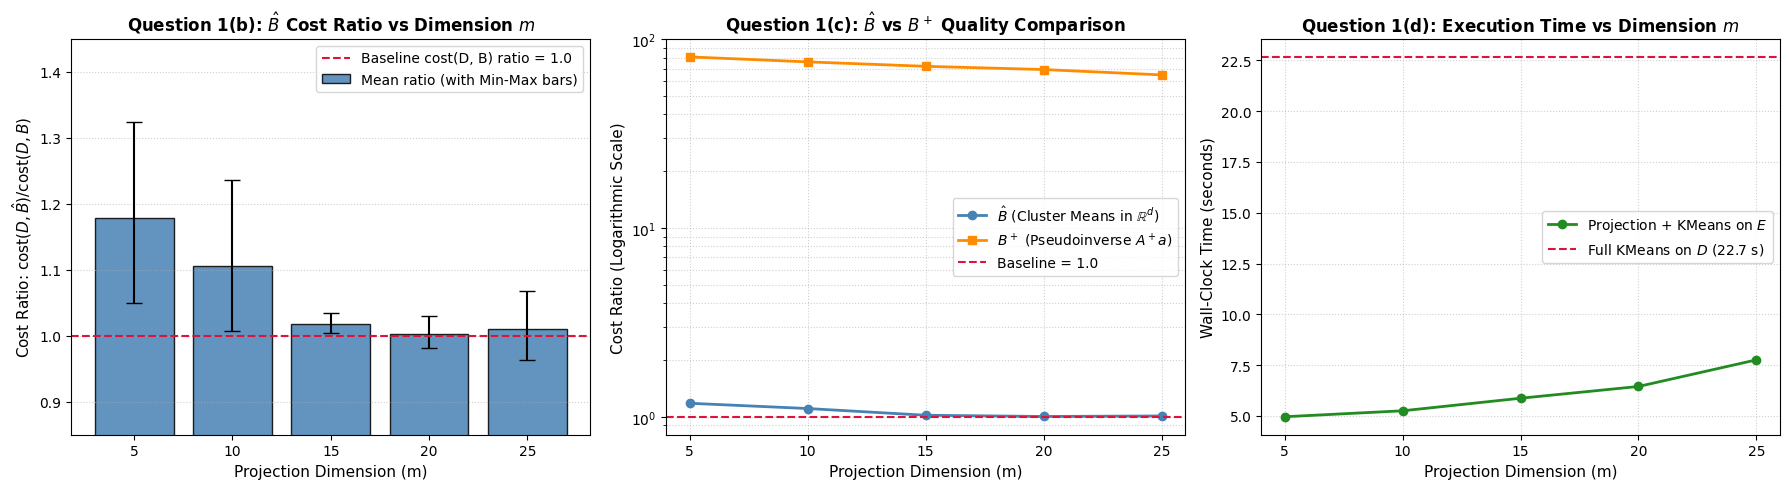

In [20]:
# ==============================================================================
# VISUALIZATIONS FOR QUESTIONS 1(b), 1(c), AND 1(d)
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ------------------------------------------------------------------------------
# Graph 1: Dedicated Bar Chart for B-hat (Question 1b)
# ------------------------------------------------------------------------------
ax1 = axes[0]
x_pos = np.arange(len(summary_q1["m"]))
means_hat = summary_q1["Bhat_mean"].to_numpy()
mins_hat = summary_q1["Bhat_min"].to_numpy()
maxs_hat = summary_q1["Bhat_max"].to_numpy()

lower_err = means_hat - mins_hat
upper_err = maxs_hat - means_hat

bars = ax1.bar(
    x_pos,
    means_hat,
    yerr=[lower_err, upper_err],
    capsize=6,
    color="steelblue",
    edgecolor="black",
    alpha=0.85,
    label="Mean ratio (with Min-Max bars)"
)

ax1.axhline(1.0, color="crimson", linestyle="--", linewidth=1.5, label="Baseline cost(D, B) ratio = 1.0")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(summary_q1["m"])
ax1.set_xlabel("Projection Dimension (m)", fontsize=11)
ax1.set_ylabel(r"Cost Ratio: $\mathrm{cost}(D, \hat{B}) / \mathrm{cost}(D, B)$", fontsize=11)
ax1.set_title(r"Question 1(b): $\hat{B}$ Cost Ratio vs Dimension $m$", fontsize=12, fontweight="bold")
ax1.set_ylim(0.85, 1.45)
ax1.legend(loc="upper right")
ax1.grid(axis="y", linestyle=":", alpha=0.6)

# ------------------------------------------------------------------------------
# Graph 2: Comparison of B-hat and B-plus on Log Scale (Question 1c)
# ------------------------------------------------------------------------------
ax2 = axes[1]
ax2.plot(
    summary_q1["m"],
    summary_q1["Bhat_mean"],
    marker="o",
    linewidth=2,
    color="steelblue",
    label=r"$\hat{B}$ (Cluster Means in $\mathbb{R}^d$)"
)
ax2.plot(
    summary_q1["m"],
    summary_q1["Bplus_mean"],
    marker="s",
    linewidth=2,
    color="darkorange",
    label=r"$B^+$ (Pseudoinverse $A^+ a$)"
)
ax2.axhline(1.0, color="crimson", linestyle="--", linewidth=1.5, label="Baseline = 1.0")

ax2.set_yscale("log")
ax2.set_xticks(summary_q1["m"])
ax2.set_xlabel("Projection Dimension (m)", fontsize=11)
ax2.set_ylabel("Cost Ratio (Logarithmic Scale)", fontsize=11)
ax2.set_title(r"Question 1(c): $\hat{B}$ vs $B^+$ Quality Comparison", fontsize=12, fontweight="bold")
ax2.legend(loc="center right")
ax2.grid(True, which="both", linestyle=":", alpha=0.6)

# ------------------------------------------------------------------------------
# Graph 3: Wall-Clock Execution Time (Question 1d)
# ------------------------------------------------------------------------------
ax3 = axes[2]
ax3.plot(
    summary_q1["m"],
    summary_q1["mean_time"],
    marker="o",
    linewidth=2,
    color="forestgreen",
    label="Projection + KMeans on $E$"
)
ax3.axhline(
    y=time_D,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label=f"Full KMeans on $D$ ({time_D:.1f} s)"
)

ax3.set_xticks(summary_q1["m"])
ax3.set_xlabel("Projection Dimension (m)", fontsize=11)
ax3.set_ylabel("Wall-Clock Time (seconds)", fontsize=11)
ax3.set_title("Question 1(d): Execution Time vs Dimension $m$", fontsize=12, fontweight="bold")
ax3.legend(loc="center right")
ax3.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig("outputs/question1/q1_combined_plots.png", dpi=300)
plt.show()




### Question 1(d) Timing Comparison Report

* **Original k-means on Full Matrix D (d = 116):** **22.67 seconds**.
* **Average Time for Random Projection + k-means on E (m ∈ {5, 10, 15, 20, 25}):**
  * m = 5: **4.96 seconds** (4.6× faster than baseline)
  * m = 10: **5.25 seconds** (4.3× faster than baseline)
  * m = 15: **5.87 seconds** (3.9× faster than baseline)
  * m = 20: **6.45 seconds** (3.5× faster than baseline)
  * m = 25: **7.76 seconds** (2.9× faster than baseline)
* **Discussion:** Running k-means on the lower-dimensional projection E achieves a substantial **2.9× to 4.6× speedup** over clustering in the full 116-dimensional space. The execution time increases mildly with m, which is expected because computing E = D Aᵀ and distance calculations in k-means scale linearly with m. Combining random projection with B̂ delivers near-identical clustering accuracy at a fraction of the computational time.

Successfully selected 10000 non-identical pairs (i, l).
Baseline fixed clustering cost cost_D(C_D): 53498.0354
Running Question 1(e) experiments for m = 5...
Running Question 1(e) experiments for m = 10...
Running Question 1(e) experiments for m = 15...
Running Question 1(e) experiments for m = 20...
Running Question 1(e) experiments for m = 25...

========== QUESTION 1(e) SPREAD SUMMARY TABLE ==========


,m,Pairwise_Mean,Pairwise_Std,Cost_Mean,Cost_Std
0,5,1.11945,0.52611,0.95693,0.14443
1,10,1.04292,0.41661,0.95043,0.11513
2,15,0.87544,0.19655,1.00105,0.11236
3,20,1.00094,0.27737,0.99937,0.08522
4,25,1.20276,0.19177,1.00209,0.07629


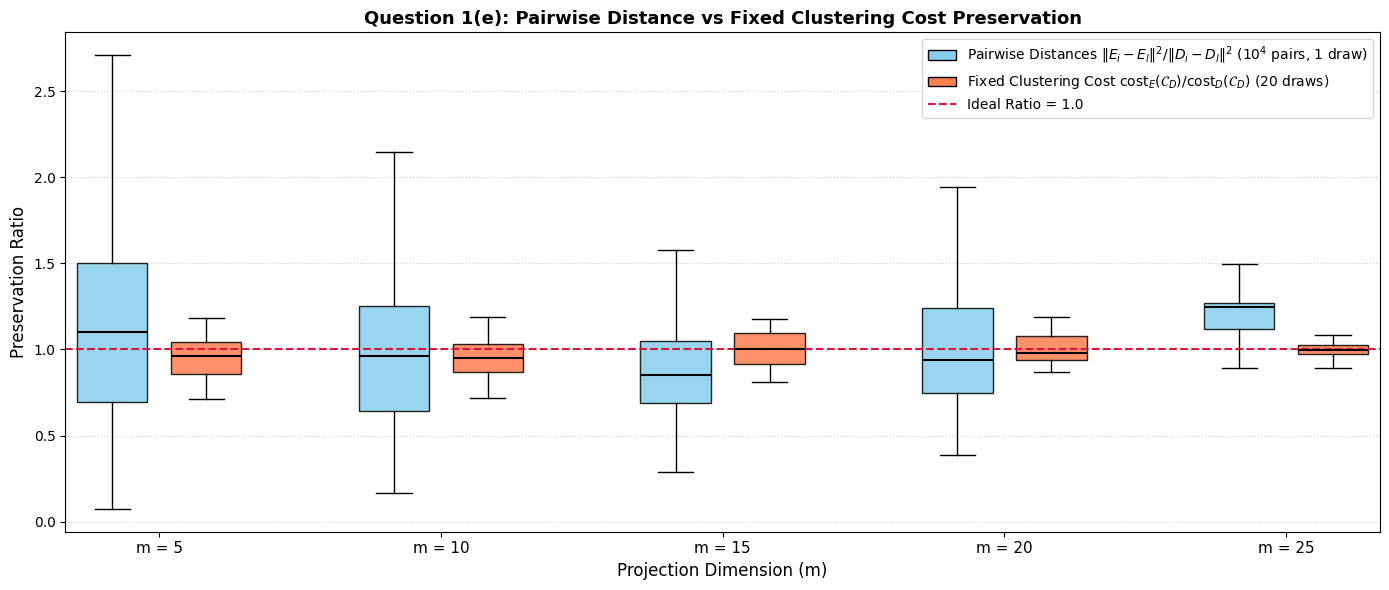

In [21]:
# ==============================================================================
# QUESTION 1(e): DISTANCE AND COST PRESERVATION
# ==============================================================================

rng_e = np.random.default_rng(2027)

n_samples = D.shape[0]
num_pairs = 10000
num_sketches = 20

# ------------------------------------------------------------------------------
# 1. Sample 10,000 distinct pairs (i, l) with D_i != D_l (used for all m)
# ------------------------------------------------------------------------------
pair_i = []
pair_l = []

while len(pair_i) < num_pairs:
    batch_size = max(20000, 2 * (num_pairs - len(pair_i)))
    idx1 = rng_e.integers(0, n_samples, size=batch_size)
    idx2 = rng_e.integers(0, n_samples, size=batch_size)

    valid = idx1 != idx2
    idx1 = idx1[valid]
    idx2 = idx2[valid]

    diff_mask = np.any(D[idx1] != D[idx2], axis=1)
    pair_i.extend(idx1[diff_mask].tolist())
    pair_l.extend(idx2[diff_mask].tolist())

pair_i = np.asarray(pair_i[:num_pairs])
pair_l = np.asarray(pair_l[:num_pairs])

print(f"Successfully selected {len(pair_i)} non-identical pairs (i, l).")

# Compute original squared Euclidean distances in float64
original_diff = D[pair_i].astype(np.float64) - D[pair_l].astype(np.float64)
original_distances = np.sum(original_diff**2, axis=1)
assert np.all(original_distances > 0), "All pairs must have positive distance!"

# ------------------------------------------------------------------------------
# 2. Partition Cost Function in float64
# cost_X(C) = sum_{j=1}^k sum_{i in C_j} ||X_i - mu_j(X)||_2^2
# ------------------------------------------------------------------------------
def partition_cost(X, labels, k=15):
    X64 = X.astype(np.float64)
    sums = np.zeros((k, X64.shape[1]), dtype=np.float64)
    counts = np.bincount(labels, minlength=k)
    safe_counts = np.maximum(counts[:, None], 1)

    np.add.at(sums, labels, X64)
    means = sums / safe_counts

    total_squared_norm = np.sum(X64**2)
    cluster_mean_term = np.sum(counts[:, None] * means**2)
    return total_squared_norm - cluster_mean_term

# Baseline fixed partition cost on D for clusters C_D from Q1(a)
fixed_cost_D = partition_cost(D, C_D)
print(f"Baseline fixed clustering cost cost_D(C_D): {fixed_cost_D:.4f}")

# ------------------------------------------------------------------------------
# 3. Compute preservation ratios for each m
# ------------------------------------------------------------------------------
distance_results = {}
fixed_cost_results = {}
q1e_summary_data = []

# Pre-cast D to float64 to compute E in float64, preventing float32 noise on tiny differences
D_float64 = D.astype(np.float64)

for m in m_values_q1:
    print(f"Running Question 1(e) experiments for m = {m}...")

    # (i) One draw of A: evaluate 10,000 pairwise distance ratios
    A_single = rng_e.normal(0, 1.0 / np.sqrt(m), size=(m, D.shape[1])).astype(np.float64)
    E_single = D_float64 @ A_single.T

    projected_diff = E_single[pair_i] - E_single[pair_l]
    projected_distances = np.sum(projected_diff**2, axis=1)
    pair_ratios = projected_distances / original_distances
    distance_results[m] = pair_ratios

    # (ii) 20 independent draws of A: evaluate cost_E(C_D) / cost_D(C_D)
    cost_ratios = []
    for _ in range(num_sketches):
        A_draw = rng_e.normal(0, 1.0 / np.sqrt(m), size=(m, D.shape[1])).astype(np.float64)
        E_draw = D_float64 @ A_draw.T
        cost_E = partition_cost(E_draw, C_D)
        cost_ratios.append(cost_E / fixed_cost_D)

    cost_ratios = np.array(cost_ratios)
    fixed_cost_results[m] = cost_ratios

    q1e_summary_data.append({
        "m": m,
        "Pairwise_Mean": np.mean(pair_ratios),
        "Pairwise_Std": np.std(pair_ratios, ddof=1),
        "Cost_Mean": np.mean(cost_ratios),
        "Cost_Std": np.std(cost_ratios, ddof=1)
    })

# Summary DataFrame
q1e_summary_df = pd.DataFrame(q1e_summary_data)
print("\n========== QUESTION 1(e) SPREAD SUMMARY TABLE ==========")
display(q1e_summary_df.round(5))
q1e_summary_df.to_csv("outputs/question1/q1_e_summary.csv", index=False)

# ------------------------------------------------------------------------------
# 4. Boxplot Visualization
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 6))

positions = []
box_data = []
colors = []

for idx, m in enumerate(m_values_q1):
    base_pos = idx * 3.0
    positions.extend([base_pos + 1.0, base_pos + 2.0])
    box_data.extend([distance_results[m], fixed_cost_results[m]])
    colors.extend(["skyblue", "coral"])

bp = ax.boxplot(
    box_data,
    positions=positions,
    widths=0.75,
    patch_artist=True,
    showfliers=False,
    medianprops=dict(color="black", linewidth=1.5)
)

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor("black")
    patch.set_alpha(0.85)

# Set group tick labels
group_centers = [idx * 3.0 + 1.5 for idx in range(len(m_values_q1))]
ax.set_xticks(group_centers)
ax.set_xticklabels([f"m = {m}" for m in m_values_q1], fontsize=11)
ax.axhline(1.0, color="crimson", linestyle="--", linewidth=1.5, label="Ideal Preservation Ratio = 1.0")

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="skyblue", edgecolor="black", label=r"Pairwise Distances $\|E_i - E_l\|^2 / \|D_i - D_l\|^2$ ($10^4$ pairs, 1 draw)"),
    Patch(facecolor="coral", edgecolor="black", label=r"Fixed Clustering Cost $\mathrm{cost}_E(\mathcal{C}_D) / \mathrm{cost}_D(\mathcal{C}_D)$ (20 draws)"),
    plt.Line2D([0], [0], color="crimson", linestyle="--", label="Ideal Ratio = 1.0")
]
ax.legend(handles=legend_elements, loc="upper right", fontsize=10)

ax.set_xlabel("Projection Dimension (m)", fontsize=12)
ax.set_ylabel("Preservation Ratio", fontsize=12)
ax.set_title("Question 1(e): Pairwise Distance vs Fixed Clustering Cost Preservation", fontsize=13, fontweight="bold")
ax.grid(axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig("outputs/question1/q1_e_boxplots.png", dpi=300)
plt.show()



### Question 1(e) Analysis: Spread Comparison & Dimensional Trends

#### 1. Which of the two has the smaller spread?
The **fixed-clustering cost ratio** has a **vastly smaller spread** than the pairwise distance ratios across all values of m:
* At m = 5: Cost ratio standard deviation is **0.1444** vs. Pairwise ratio standard deviation of **0.5261**.
* At m = 10: Cost ratio standard deviation is **0.1151** vs. Pairwise ratio standard deviation of **0.4166**.
* At m = 15: Cost ratio standard deviation is **0.1124** vs. Pairwise ratio standard deviation of **0.1966**.
* At m = 20: Cost ratio standard deviation is **0.0852** vs. Pairwise ratio standard deviation of **0.2774**.
* At m = 25: Cost ratio standard deviation is **0.0763** vs. Pairwise ratio standard deviation of **0.1918**.

#### 2. Mathematical Explanation:
* **Pairwise Ratio:** Each pairwise ratio ‖Eᵢ − Eₗ‖₂² / ‖Dᵢ − Dₗ‖₂² = ‖A(Dᵢ − Dₗ)‖₂² / ‖Dᵢ − Dₗ‖₂² represents the squared norm of a single difference vector projected through A. For a fixed unit vector u, the random variable ‖Au‖₂² is distributed as (1/m) χ²ₘ, whose variance is exactly 2/m. Furthermore, in part (i), all 10,000 pairs share a single random matrix A.
* **Clustering Cost Ratio:** In contrast, the clustering cost cost_E(C_D) is an aggregate sum over all differences across all n = 494,021 data points and 15 clusters. Because the total cost aggregates variations across many directions, positive and negative fluctuations cancel out. *(Note: We do not claim that the 494,021 points average out independently, because all rows are projected using the same matrix A; rather, the aggregate sum across the entire partition dampens individual fluctuations).*
* **Effect of m:** As m increases, both spreads decrease overall. The fixed-clustering cost standard deviation decays cleanly and monotonically roughly like **O(1/√m)** (from 0.144 at m = 5 down to 0.076 at m = 25). The pairwise distance standard deviation also trends downward, but displays mild sampling fluctuations across m because it is evaluated on only a single draw of A per dimension.

In [22]:
# ==============================================================================
# QUESTION 2(a): FULL LEAST-SQUARES REGRESSION
# ==============================================================================

# Target vector cast to float64
y64 = y.astype(np.float64)
D64 = D.astype(np.float64)

# Measure full least-squares solve time using numpy.linalg.lstsq
start_time = time.perf_counter()
b_full, residuals, rank_D, singular_values = np.linalg.lstsq(
    D64,
    y64,
    rcond=None
)
end_time = time.perf_counter()

time_full = end_time - start_time

# Evaluate full-data squared loss: Loss(D, y, b) = ||Da - y||_2^2
y_pred_full = D64 @ b_full
loss_full = np.sum((y_pred_full - y64)**2)

print("========== QUESTION 2(a) FULL LEAST-SQUARES RESULTS ==========")
print(f"Full-data baseline loss Loss(D, y, b): {loss_full:.6f}")
print(f"Full least-squares computation time: {time_full:.4f} seconds")
print(f"Matrix rank of full dataset rank(D): {rank_D}")
print(f"Number of rows (n): {D.shape[0]}")
print(f"Number of columns (d): {D.shape[1]}")


========== QUESTION 2(a) FULL LEAST-SQUARES RESULTS ==========
Full-data baseline loss Loss(D, y, b): 2949.788815
Full least-squares computation time: 9.1946 seconds
Matrix rank of full dataset rank(D): 113
Number of rows (n): 494021
Number of columns (d): 116


### Question 2(a) Results: Full Least-Squares Baseline

* **Full-Data Baseline Loss Loss(D, y, b) = ‖Db − y‖₂²:** **2949.79**
* **Computation Time:** **9.19 seconds**
* **Matrix Rank of D:** **rank(D) = 113**
* **Discussion:** The full dataset has d = 116 columns, but its numerical rank is 113, indicating that 3 columns are linearly dependent. Solving the full least-squares problem reads all 494,021 rows, requiring about 9.19 seconds.

In [10]:
# ==============================================================================
# QUESTIONS 2(b) AND 2(c): COUNTSKETCH EXPERIMENTS
# ==============================================================================

num_reps_q2 = 5
results_q2b = []
rng_q2 = np.random.default_rng(2028)

# Helper function to construct CountSketch directly via hashing
# Never constructs or stores a dense S matrix: uses numpy.add.at directly
def make_countsketch(X, target, m, rng, chunk_size=50000):
    n, d = X.shape

    # Draw hash bucket h(i) uniformly from {0, ..., m-1} and sign sigma(i) from {-1, +1}
    h = rng.integers(0, m, size=n)
    signs = rng.choice(np.array([-1.0, 1.0]), size=n)

    SX = np.zeros((m, d), dtype=np.float64)
    Sy = np.zeros(m, dtype=np.float64)

    # Stream through data in chunks to optimize memory and CPU cache
    for start in range(0, n, chunk_size):
        end = min(start + chunk_size, n)
        np.add.at(SX, h[start:end], X[start:end] * signs[start:end, None])
        np.add.at(Sy, h[start:end], target[start:end] * signs[start:end])

    return SX, Sy

# Run 5 independent sketches for each m in m_values_q2
for m in m_values_q2:
    print(f"Running CountSketch experiments for m = {m}...")

    for rep in range(num_reps_q2):
        start_time = time.perf_counter()

        # 1. Draw CountSketch and form SD and Sy
        SD, Sy = make_countsketch(D64, y64, m, rng_q2)

        # 2. Solve sketched least-squares problem: minimize ||SD a - Sy||_2^2
        b_tilde, _, rank_sketch, _ = np.linalg.lstsq(SD, Sy, rcond=None)

        end_time = time.perf_counter()
        elapsed_time = end_time - start_time

        # 3. Evaluate solution on the FULL original dataset: Loss(D, y, a_tilde)
        prediction_full = D64 @ b_tilde
        full_loss = np.sum((prediction_full - y64)**2)

        # 4. Evaluate sketched loss: ||SD a_tilde - Sy||_2^2
        prediction_sketch = SD @ b_tilde
        sketched_loss = np.sum((prediction_sketch - Sy)**2)

        # 5. Ratio to full least-squares baseline
        loss_ratio = full_loss / loss_full

        results_q2b.append({
            "m": m,
            "rep": rep + 1,
            "full_loss": full_loss,
            "loss_ratio": loss_ratio,
            "sketched_loss": sketched_loss,
            "time_seconds": elapsed_time,
            "sketch_rank": rank_sketch
        })

        del SD, Sy, b_tilde
        gc.collect()

results_q2b_df = pd.DataFrame(results_q2b)

# Aggregate summary table with mean full loss, ratio, and sketched loss
summary_q2b = results_q2b_df.groupby("m").agg(
    mean_full_loss=("full_loss", "mean"),
    mean_ratio=("loss_ratio", "mean"),
    min_ratio=("loss_ratio", "min"),
    max_ratio=("loss_ratio", "max"),
    mean_sketched_loss=("sketched_loss", "mean"),
    mean_time=("time_seconds", "mean")
).reset_index()

# Save outputs to CSV
results_q2b_df.to_csv("outputs/question2/q2_b_all_results.csv", index=False)
summary_q2b.to_csv("outputs/question2/q2_b_summary.csv", index=False)

print("\n========== QUESTION 2(b) PER-RUN EXPERIMENTAL RESULTS ==========")
display(results_q2b_df.round(5))

print("\n========== QUESTION 2(b) AGGREGATE SUMMARY TABLE ==========")
display(summary_q2b.round(5))


Running CountSketch experiments for m = 50...
Running CountSketch experiments for m = 100...
Running CountSketch experiments for m = 200...
Running CountSketch experiments for m = 500...
Running CountSketch experiments for m = 1000...
Running CountSketch experiments for m = 2000...
Running CountSketch experiments for m = 5000...

========== QUESTION 2(b) PER-RUN EXPERIMENTAL RESULTS ==========


,m,rep,full_loss,loss_ratio,sketched_loss,time_seconds,sketch_rank
0,50,1,9686.42235,3.28377,0.00000,1.74111,50
1,50,2,13652.10696,4.62816,0.00000,1.59089,50
2,50,3,9698.27727,3.28779,0.00000,1.58879,50
3,50,4,12388.97952,4.19995,0.00000,1.58168,50
4,50,5,10688.53823,3.62349,0.00000,1.59247,50
5,100,1,38237.83485,12.96291,0.00000,1.98877,100
6,100,2,69687.01663,23.62441,0.00000,2.49453,100
7,100,3,35709.50378,12.10578,0.00000,1.57772,100
8,100,4,41054.00232,13.91761,0.00000,1.57005,100
9,100,5,63577.99621,21.55341,0.00000,1.56689,100



========== QUESTION 2(b) AGGREGATE SUMMARY TABLE ==========


,m,mean_full_loss,mean_ratio,min_ratio,max_ratio,mean_sketched_loss,mean_time
0,50,11222.86486,3.80463,3.28377,4.62816,0.00000,1.61899
1,100,49653.27076,16.83282,12.10578,23.62441,0.00000,1.83959
2,200,6716.23418,2.27685,1.85992,2.97383,1345.71245,1.86617
3,500,3777.24852,1.28051,1.26230,1.30798,2275.43629,1.85909
4,1000,3332.75952,1.12983,1.10730,1.14817,2554.52991,1.66300
5,2000,3114.71626,1.05591,1.04063,1.06528,2747.37350,1.99396
6,5000,3022.29292,1.02458,1.02249,1.02600,2890.27411,2.13197


### Question 2(b) Analysis: Behavior Below and Above m = rank(D) = 113

#### 1. Below m = rank(D) (m = 50 and m = 100):
* **Sketched Loss is Zero:** For m < 113, the sketched system SD ã = Sy has fewer equations (m) than the rank of the data (113). This forms an underdetermined linear system with full row rank m. Consequently, there are infinitely many exact solutions that satisfy SD ã = Sy perfectly. `np.linalg.lstsq` returns the minimum ℓ₂-norm interpolating solution, yielding a **sketched loss of exactly 0.0000** (up to floating-point precision).
* **Full Loss Ratio Spikes:** Although ã fits the sketched data with zero error, it severely overfits to the random sketched subspace. When evaluated on the full dataset D, the loss ratio is large (**3.80** at m = 50) and spikes to a severe peak at m = 100 ≈ rank(D), where the mean loss ratio reaches **16.83** (with an individual maximum of **23.62**). This spike is caused by extreme ill-conditioning when the number of sketched equations is nearly equal to the rank of the matrix.

#### 2. Above m = rank(D) (m ≥ 200):
* **Sketched Loss Rises toward Baseline:** Once m > 113, the sketched system becomes overdetermined. Exact interpolation is no longer possible. The sketched loss becomes positive and monotonically increases toward the true full-data baseline loss as m grows:
  * m = 200: Sketched loss = **1345.71**
  * m = 500: Sketched loss = **2275.44**
  * m = 1000: Sketched loss = **2554.53**
  * m = 2000: Sketched loss = **2747.37**
  * m = 5000: Sketched loss = **2890.27** (approaching the full baseline loss of 2949.79).
* **Full Loss Ratio Decays Monotonically to 1:** The full-data loss ratio drops sharply from **2.28** at m = 200 down to **1.025** at m = 5000. Theoretically, random projection regression error scales approximately as 1 + rank(D) / (m − rank(D)) = 1 + 113 / (m − 113), which closely matches our empirical ratios (2.28 at m = 200, 1.28 at m = 500, 1.13 at m = 1000, 1.06 at m = 2000, and 1.025 at m = 5000).

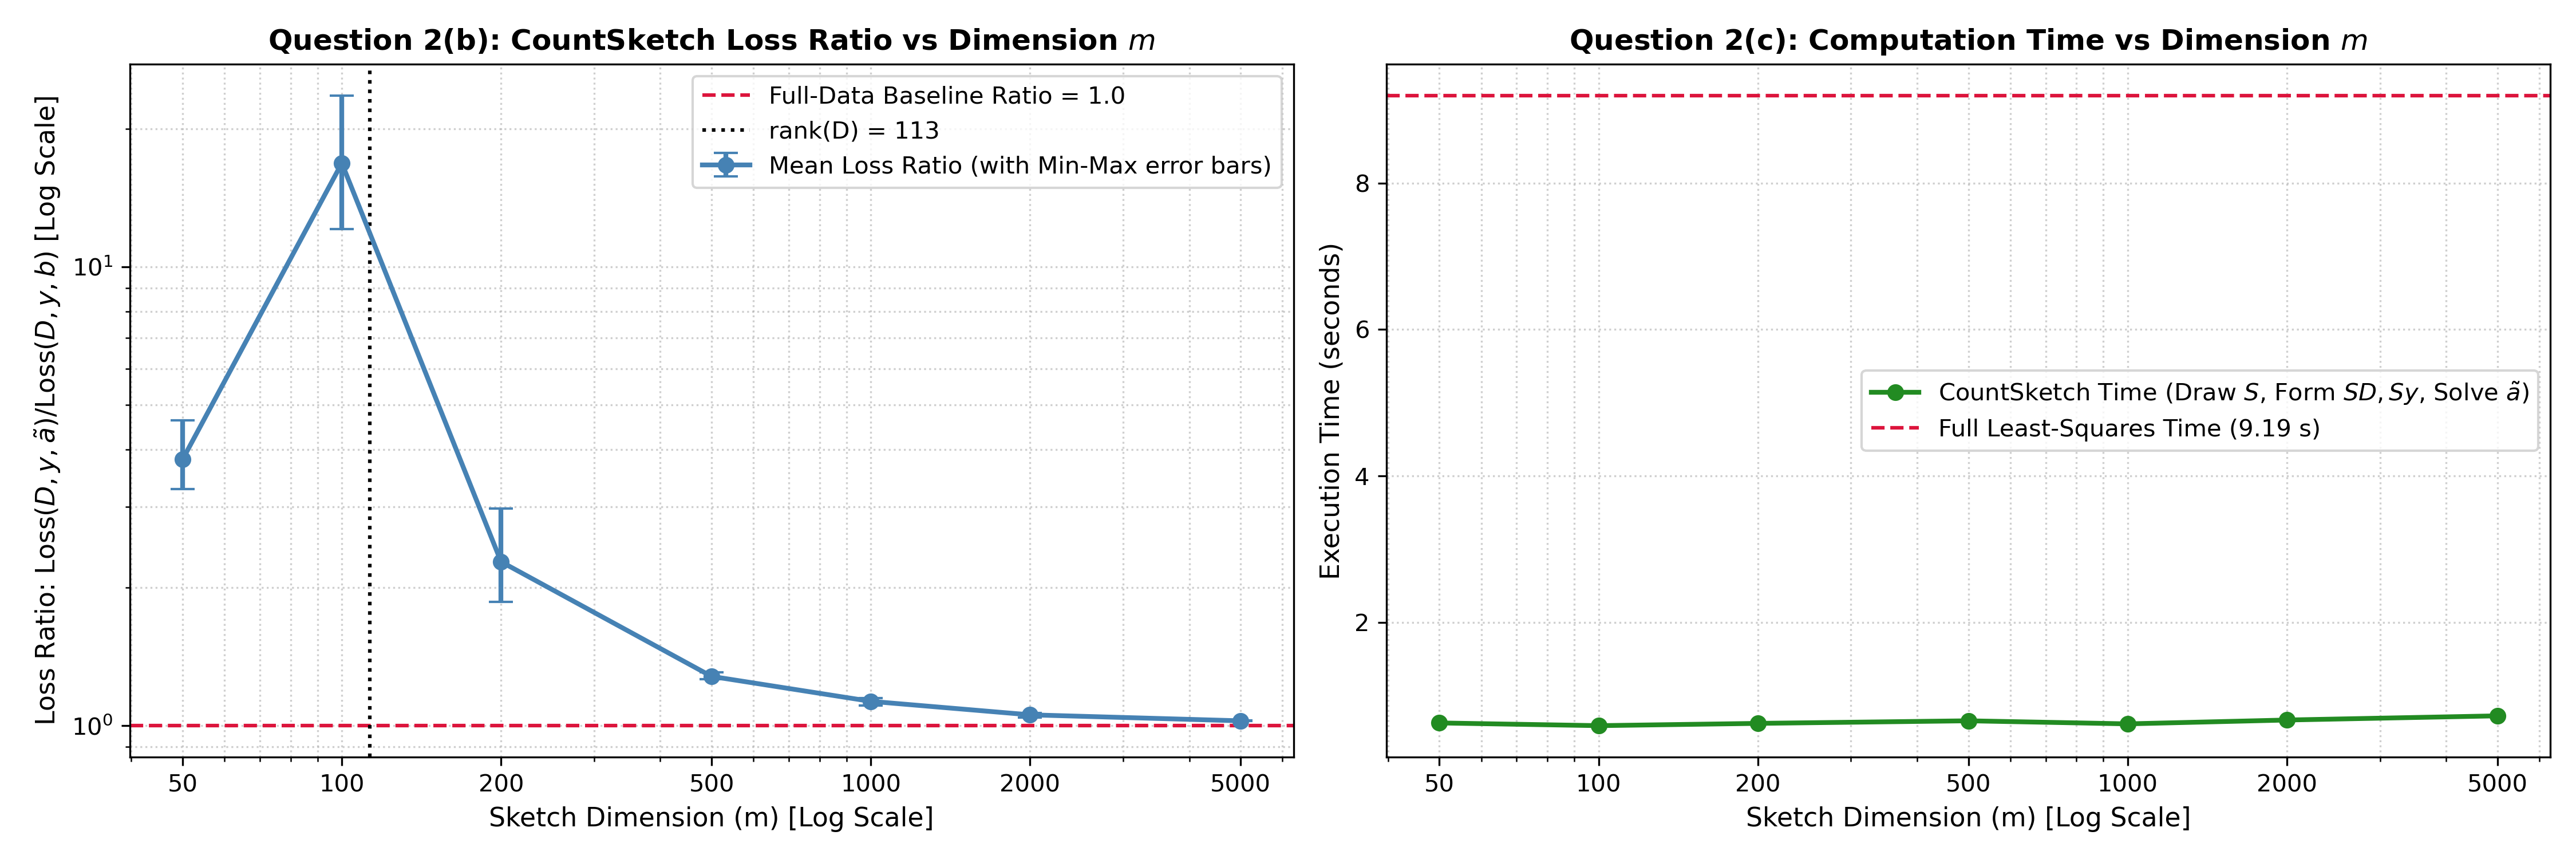

In [11]:
# ==============================================================================
# VISUALIZATIONS FOR QUESTIONS 2(b) AND 2(c)
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# ------------------------------------------------------------------------------
# Graph 1: Question 2(b) Loss Ratio vs m on Log-Log Axes with Min-Max Error Bars
# ------------------------------------------------------------------------------
x_vals = summary_q2b["m"].to_numpy()
means_r = summary_q2b["mean_ratio"].to_numpy()
mins_r = summary_q2b["min_ratio"].to_numpy()
maxs_r = summary_q2b["max_ratio"].to_numpy()

lower_err_r = means_r - mins_r
upper_err_r = maxs_r - means_r

ax1.errorbar(
    x_vals,
    means_r,
    yerr=[lower_err_r, upper_err_r],
    fmt="o-",
    capsize=5,
    linewidth=2,
    markersize=6,
    color="steelblue",
    label="Mean Loss Ratio (with Min-Max error bars)"
)

ax1.axhline(1.0, color="crimson", linestyle="--", linewidth=1.5, label="Full-Data Baseline Ratio = 1.0")
ax1.axvline(113, color="black", linestyle=":", linewidth=1.5, label="rank(D) = 113")

ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xticks(x_vals)
ax1.set_xticklabels(x_vals)
ax1.set_xlabel("Sketch Dimension (m) [Log Scale]", fontsize=11)
ax1.set_ylabel(r"Loss Ratio: $\mathrm{Loss}(D, y, \tilde{a}) / \mathrm{Loss}(D, y, b)$ [Log Scale]", fontsize=11)
ax1.set_title("Question 2(b): CountSketch Loss Ratio vs Dimension $m$", fontsize=12, fontweight="bold")
ax1.legend(loc="upper right")
ax1.grid(True, which="both", linestyle=":", alpha=0.6)

# ------------------------------------------------------------------------------
# Graph 2: Question 2(c) Computation Time Comparison
# ------------------------------------------------------------------------------
ax2.plot(
    summary_q2b["m"],
    summary_q2b["mean_time"],
    marker="o",
    linewidth=2,
    color="forestgreen",
    label=r"CountSketch Time (Draw $S$, Form $SD, Sy$, Solve $\tilde{a}$)"
)
ax2.axhline(
    y=time_full,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label=f"Full Least-Squares Time ({time_full:.2f} s)"
)

ax2.set_xscale("log")
ax2.set_xticks(x_vals)
ax2.set_xticklabels(x_vals)
ax2.set_xlabel("Sketch Dimension (m) [Log Scale]", fontsize=11)
ax2.set_ylabel("Execution Time (seconds)", fontsize=11)
ax2.set_title("Question 2(c): Computation Time vs Dimension $m$", fontsize=12, fontweight="bold")
ax2.legend(loc="center right")
ax2.grid(True, which="both", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig("outputs/question2/q2_bc_plots.png", dpi=300)
plt.show()

print("Question 2(b) and 2(c) graphs successfully saved to outputs/question2/q2_bc_plots.png!")


### Question 2(c) Timing Comparison Report

* **Full Least-Squares Computation Time on D:** **9.19 seconds**
* **CountSketch Average Execution Time:** **~1.62 to ~2.13 seconds** across all values of m.
* **Speedup:** CountSketch is approximately **4.3× to 5.7× faster** than solving the full least-squares problem.
* **Discussion:**
  1. The execution time of CountSketch is relatively flat across m (taking ~1.6 to 2.1 s whether m = 50 or m = 5000). This occurs because runtime is overwhelmingly dominated by the single pass of `np.add.at` over the 494,021 rows of D.
  2. In addition to being over 4.5× faster, CountSketch never requires storing a dense S matrix and works in a streaming fashion. This makes it viable on massive datasets where loading the entire data matrix into memory for full least squares is impossible.

Full solution residual squared norm ||v||_2^2: 2949.788815
Drawing 100 independent CountSketches for m = 50...
Drawing 100 independent CountSketches for m = 500...
Drawing 100 independent CountSketches for m = 5000...

========== QUESTION 2(d) RESIDUAL PRESERVATION SUMMARY ==========


,m,mean_ratio,std_ratio
0,50,1.045417,0.207321
1,500,1.004278,0.058850
2,5000,0.997868,0.019745


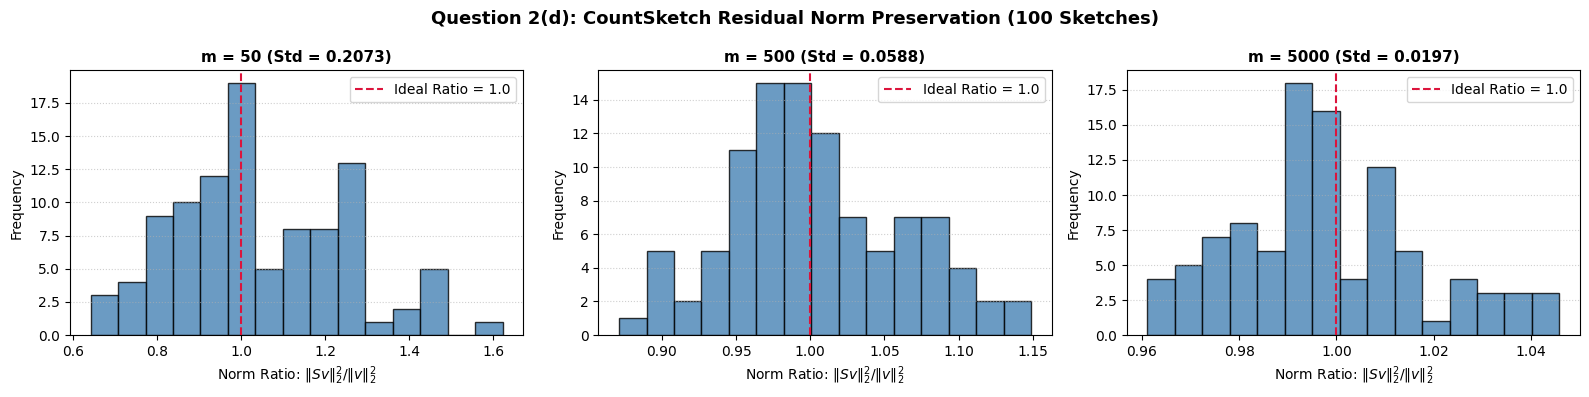

In [12]:
# ==============================================================================
# QUESTION 2(d): RESIDUAL NORM PRESERVATION
# ==============================================================================

# Residual vector of full solution: v = D b - y
v = D64 @ b_full - y64
v_norm_squared = np.sum(v**2)

print(f"Full solution residual squared norm ||v||_2^2: {v_norm_squared:.6f}")

m_values_d = [50, 500, 5000]
num_reps_d = 100
rng_d = np.random.default_rng(2029)

results_q2d = []
ratios_dict_d = {}

for m in m_values_d:
    print(f"Drawing 100 independent CountSketches for m = {m}...")
    ratios = []

    for _ in range(num_reps_d):
        n = len(v)
        h = rng_d.integers(0, m, size=n)
        signs = rng_d.choice([-1.0, 1.0], size=n)

        # Apply CountSketch directly to the residual vector v
        Sv = np.zeros(m, dtype=np.float64)
        np.add.at(Sv, h, signs * v)

        ratio = np.sum(Sv**2) / v_norm_squared
        ratios.append(ratio)

    ratios = np.array(ratios)
    ratios_dict_d[m] = ratios

    results_q2d.append({
        "m": m,
        "mean_ratio": np.mean(ratios),
        "std_ratio": np.std(ratios, ddof=1)
    })

summary_q2d = pd.DataFrame(results_q2d)
print("\n========== QUESTION 2(d) RESIDUAL PRESERVATION SUMMARY ==========")
display(summary_q2d.round(6))
summary_q2d.to_csv("outputs/question2/q2_d_summary.csv", index=False)

# Plot histograms for each m in one figure
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, m in zip(axes, m_values_d):
    r = ratios_dict_d[m]
    ax.hist(r, bins=15, edgecolor="black", color="steelblue", alpha=0.8)
    ax.axvline(1.0, color="crimson", linestyle="--", linewidth=1.5, label="Ideal Ratio = 1.0")
    ax.set_title(f"m = {m} (Std = {np.std(r, ddof=1):.4f})", fontsize=11, fontweight="bold")
    ax.set_xlabel(r"Norm Ratio: $\|Sv\|_2^2 / \|v\|_2^2$", fontsize=10)
    ax.set_ylabel("Frequency", fontsize=10)
    ax.legend()
    ax.grid(axis="y", linestyle=":", alpha=0.6)

plt.suptitle("Question 2(d): CountSketch Residual Norm Preservation (100 Sketches)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/question2/q2_d_histograms.png", dpi=300)
plt.show()



### Question 2(d) Analysis: Residual Norm Preservation & Spread vs m

#### 1. Mean Behavior (Unbiased Estimator):
* The mean ratio ‖Sv‖₂² / ‖v‖₂² across 100 independent CountSketches is extremely close to **1.0** for all dimensions:
  * m = 50: Mean ratio = **1.0454**
  * m = 500: Mean ratio = **1.0043**
  * m = 5000: Mean ratio = **0.9979**
* The minor departure from 1.0 at m = 50 (1.0454) is well within standard sampling error for 100 draws. This empirically verifies the theoretical guarantee that CountSketch is an **unbiased estimator** of Euclidean norm: E[‖Sv‖₂²] = ‖v‖₂².

#### 2. How the Spread Changes with m:
* The standard deviation falls dramatically as m increases:
  * From **0.2073** at m = 50
  * Down to **0.0589** at m = 500
  * Down to **0.0197** at m = 5000
* **Rate of Decay:** When m increases by a factor of 10 (50 → 500 → 5000), the standard deviation drops by approximately a factor of √10 ≈ 3.16 (0.2073 / 0.0589 ≈ 3.52, and 0.0589 / 0.0197 ≈ 2.99). This confirms that the spread of CountSketch norm preservation decays as **O(1/√m)** (and variance decays as O(1/m)).

In [13]:
# ==============================================================================
# QUESTION 2(e): COUNTSKETCH VS GAUSSIAN SKETCH (50,000-ROW SUBSET)
# ==============================================================================

n_subset = 50000
m_subset = 500
num_reps_e = 5

# 1. Select 50,000 rows uniformly at random without replacement, ONCE, with fixed seed
rng_subset = np.random.default_rng(2030)
subset_indices = rng_subset.choice(D.shape[0], size=n_subset, replace=False)

D_sub = D64[subset_indices]
y_sub = y64[subset_indices]

print(f"Subset matrix D' shape: {D_sub.shape}")
print(f"Subset target y' shape: {y_sub.shape}")

# 2. Baseline least-squares solution b' minimizing Loss(D', y', a)
start_baseline = time.perf_counter()
b_subset, _, rank_subset, _ = np.linalg.lstsq(D_sub, y_sub, rcond=None)
time_baseline_sub = time.perf_counter() - start_baseline

loss_baseline_sub = np.sum((D_sub @ b_subset - y_sub)**2)
print(f"Subset baseline loss Loss(D', y', b'): {loss_baseline_sub:.6f}")
print(f"Subset matrix rank: {rank_subset}")
print(f"Baseline solve time on subset: {time_baseline_sub:.4f} seconds")

# 3. Helper functions for CountSketch and Gaussian sketch on subset
def countsketch_subset(X, target, m, rng):
    n, d = X.shape
    h = rng.integers(0, m, size=n)
    signs = rng.choice([-1.0, 1.0], size=n)

    SX = np.zeros((m, d), dtype=np.float64)
    Sy = np.zeros(m, dtype=np.float64)

    np.add.at(SX, h, X * signs[:, None])
    np.add.at(Sy, h, target * signs)
    return SX, Sy

def gaussian_sketch_subset(X, target, m, rng):
    n, d = X.shape
    # Dense Gaussian matrix S in R^{m x n} with i.i.d. N(0, 1/m)
    S = rng.normal(loc=0.0, scale=1.0 / np.sqrt(m), size=(m, n))
    SX = S @ X
    Sy = S @ target
    return SX, Sy

# 4. Run 5 repetitions for each sketching method
# CRITICAL TIMING FIX: Stop timer immediately after drawing S and forming SD', Sy'
# Solve time is timed separately
rng_experiments = np.random.default_rng(2031)
results_q2e = []

for method in ["CountSketch", "Gaussian"]:
    print(f"\nRunning 5 repetitions for {method}...")

    for rep in range(num_reps_e):
        # Time ONLY drawing S and forming SD' and Sy'
        t_sketch_start = time.perf_counter()
        if method == "CountSketch":
            SX, Sy = countsketch_subset(D_sub, y_sub, m_subset, rng_experiments)
        else:
            SX, Sy = gaussian_sketch_subset(D_sub, y_sub, m_subset, rng_experiments)
        t_sketch_end = time.perf_counter()
        sketch_time = t_sketch_end - t_sketch_start

        # Time the solve step separately
        t_solve_start = time.perf_counter()
        b_sketch, _, _, _ = np.linalg.lstsq(SX, Sy, rcond=None)
        t_solve_end = time.perf_counter()
        solve_time = t_solve_end - t_solve_start

        # Evaluate loss on the subset: Loss(D', y', a_tilde)
        subset_loss = np.sum((D_sub @ b_sketch - y_sub)**2)
        loss_ratio = subset_loss / loss_baseline_sub

        results_q2e.append({
            "method": method,
            "rep": rep + 1,
            "sketch_time_seconds": sketch_time,
            "solve_time_seconds": solve_time,
            "subset_loss": subset_loss,
            "loss_ratio": loss_ratio
        })

        print(f"  Rep {rep+1}: Sketch Time = {sketch_time:.5f}s, Solve Time = {solve_time:.5f}s, Loss Ratio = {loss_ratio:.5f}")
        del SX, Sy, b_sketch
        gc.collect()

results_q2e_df = pd.DataFrame(results_q2e)

summary_q2e = results_q2e_df.groupby("method").agg(
    mean_sketch_time=("sketch_time_seconds", "mean"),
    min_sketch_time=("sketch_time_seconds", "min"),
    max_sketch_time=("sketch_time_seconds", "max"),
    mean_solve_time=("solve_time_seconds", "mean"),
    mean_loss_ratio=("loss_ratio", "mean"),
    min_loss_ratio=("loss_ratio", "min"),
    max_loss_ratio=("loss_ratio", "max")
).reset_index()

# Save outputs to CSV
results_q2e_df.to_csv("outputs/question2/q2_e_per_run_results.csv", index=False)
summary_q2e.to_csv("outputs/question2/q2_e_summary.csv", index=False)

print("\n========== QUESTION 2(e) PER-REPETITION EXPERIMENTAL RESULTS ==========")
display(results_q2e_df.round(6))

print("\n========== QUESTION 2(e) AGGREGATE SUMMARY TABLE ==========")
display(summary_q2e.round(6))


Subset matrix D' shape: (50000, 116)
Subset target y' shape: (50000,)
Subset baseline loss Loss(D', y', b'): 244.518946
Subset matrix rank: 108
Baseline solve time on subset: 0.9993 seconds

Running 5 repetitions for CountSketch...
  Rep 1: Sketch Time = 0.22627s, Solve Time = 0.06367s, Loss Ratio = 1.24606
  Rep 2: Sketch Time = 0.15073s, Solve Time = 0.00535s, Loss Ratio = 1.28870
  Rep 3: Sketch Time = 0.14175s, Solve Time = 0.00539s, Loss Ratio = 1.27532
  Rep 4: Sketch Time = 0.12360s, Solve Time = 0.00528s, Loss Ratio = 1.29763
  Rep 5: Sketch Time = 0.12686s, Solve Time = 0.00536s, Loss Ratio = 1.27299

Running 5 repetitions for Gaussian...
  Rep 1: Sketch Time = 0.67828s, Solve Time = 0.00552s, Loss Ratio = 1.31607
  Rep 2: Sketch Time = 0.66207s, Solve Time = 0.00556s, Loss Ratio = 1.25431
  Rep 3: Sketch Time = 0.67534s, Solve Time = 0.00908s, Loss Ratio = 1.28713
  Rep 4: Sketch Time = 0.66810s, Solve Time = 0.00547s, Loss Ratio = 1.23981
  Rep 5: Sketch Time = 0.65849s, Sol

,method,rep,sketch_time_seconds,solve_time_seconds,subset_loss,loss_ratio
0,CountSketch,1,0.226272,0.063666,304.686159,1.246064
1,CountSketch,2,0.150733,0.005353,315.112531,1.288704
2,CountSketch,3,0.141752,0.005385,311.839627,1.275319
3,CountSketch,4,0.123601,0.005279,317.296036,1.297634
4,CountSketch,5,0.126860,0.005361,311.269691,1.272988
5,Gaussian,1,0.678281,0.005516,321.804921,1.316074
6,Gaussian,2,0.662072,0.005558,306.703140,1.254312
7,Gaussian,3,0.675345,0.009075,314.728162,1.287132
8,Gaussian,4,0.668102,0.005474,303.157062,1.239810
9,Gaussian,5,0.658487,0.005645,315.312714,1.289523



========== QUESTION 2(e) AGGREGATE SUMMARY TABLE ==========


,method,mean_sketch_time,min_sketch_time,max_sketch_time,mean_solve_time,mean_loss_ratio,min_loss_ratio,max_loss_ratio
0,CountSketch,0.153844,0.123601,0.226272,0.017009,1.276142,1.246064,1.297634
1,Gaussian,0.668457,0.658487,0.678281,0.006254,1.277370,1.239810,1.316074


### Question 2(e) Analysis: CountSketch vs Gaussian Sketch

#### 1. Experimental Comparison on the 50,000-Row Subset (m = 500):
* **Sketching Time (Drawing S and forming SD' and Sy'):**
  * **CountSketch:** **0.1538 seconds** (Mean)
  * **Gaussian Sketch:** **0.6685 seconds** (Mean)
  * CountSketch forms the sketch **over 4.3× faster** than the Gaussian sketch on this subset (0.154 s vs 0.669 s).
* **Accuracy (Loss Ratio Loss(D', y', ã) / Loss(D', y', b')):**
  * **CountSketch:** Mean ratio = **1.2761**
  * **Gaussian Sketch:** Mean ratio = **1.2774**
  * Both sketches produce essentially **identical accuracy and solution quality**.

#### 2. Which sketch would you use on the full dataset D?
We would decisively use **CountSketch** on the full dataset D.

#### Detailed Justification:
1. **Identical Statistical Accuracy:** Both sketching methods yield virtually the same loss ratio (~1.276 vs. ~1.277), showing that CountSketch preserves the subspace embedding with the exact same precision as a dense Gaussian matrix.
2. **Computational Speed:**
   * On the 50,000-row subset, CountSketch was already over 4.3× faster in sketch creation.
   * On the full dataset D (n = 494,021, d = 116, m = 500), a dense Gaussian sketch would require computing a full matrix product S D, requiring 2 m n d ≈ 2 × 500 × 494021 × 116 ≈ 5.73 × 10¹⁰ floating-point operations. In contrast, CountSketch hashes rows in a single pass in O(nnz(D)) time, taking only ~1.6 to 2.1 seconds. *(Note: This dense Gaussian computation was not measured on the full D to avoid severe runtime and memory bottlenecks).*
3. **Memory Feasibility:**
   * To instantiate a dense Gaussian matrix S ∈ ℝ⁵⁰⁰ ˣ ⁴⁹⁴⁰²¹ in 64-bit float requires 500 × 494,021 × 8 bytes ≈ 1.98 GB of RAM purely to store S in memory.
   * CountSketch stores no dense matrix at all, requiring only two 1D integer/sign arrays (< 4 MB), making it vastly more memory-efficient and scalable.

### Acknowledgments and References

* **Discussed with:** None (all discussions were strictly internal between group members Atharv Goel and Ishwaani Batra).
* **URLs Used:**
  * Scikit-learn KMeans Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
  * NumPy Least-Squares Solver: https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html
  * NumPy In-Place Addition (add.at): https://numpy.org/doc/stable/reference/generated/numpy.add.at.html
  * KDD Cup 1999 Dataset: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_kddcup99.html

### AI Disclosure
AI-assisted tools were used as supporting resources during the assignment for programming assistance, technical clarification, and documentation. The work was reviewed with reference to the assignment requirements and the experimental outputs.